# Pauta tarea 2

Se premia la idea y la interpretación por sobre el código.

60 pts, nota = 1 + 6·pts/60

| Pregunta | Pts | | Pregunta | Pts |
|---|---|---|---|---|
| P1 | 2 | | P5 (a) 5, (b) 4 | 9 |
| P2 (a) 3, (b) 2, (c) 4 | 9 | | P6 (a) 4, (b) 4 | 8 |
| P3 (a) 3, (b) 3 | 6 | | P7 (a) 4, (b) 5, (c) 4 | 13 |
| P4 (a) 5, (b) 4 | 9 | | P8 | 4 |

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

url_data = "https://raw.githubusercontent.com/victormaciase/EconometriaFinanciera_MagisterFinanzasWK/refs/heads/main/TrabajoPractico2/empresas_sp500.csv"
df = pd.read_csv(url_data)
df["lPER"] = np.log(df["TrailingPER"])
df.shape

(398, 12)

## Pregunta 1 (2 pts)
¿Cuántas empresas hay por `Sector`? ¿Cuál es el sector con más empresas?

In [ ]:
df["Sector"].value_counts()

Sector
Technology                68
Industrials               66
Financial Services        49
Healthcare                43
Consumer Cyclical         37
Utilities                 29
Consumer Defensive        26
Real Estate               25
Energy                    21
Communication Services    20
Basic Materials           14
Name: count, dtype: int64

Esperado: 398 empresas, 11 sectores. Technology (68) es el sector con más empresas, seguido de Industrials (66).

- 2 pts: tabla + nombra el sector. 1 pt: solo tabla sin responder explícitamente.

## Pregunta 2
(a) (3 pts) Estadística descriptiva del `TrailingPER` por sector.

In [ ]:
df.groupby("Sector")["TrailingPER"].agg(["min", "max", "mean", "median", "std"]).round(1)

,min,max,mean,median,std
Sector,,,,,
Basic Materials,9.5,55.4,28.0,29.0,13.2
Communication Services,3.3,340.3,46.7,19.4,81.6
Consumer Cyclical,8.1,512.3,44.7,20.0,96.2
Consumer Defensive,8.1,45.1,24.6,22.7,9.4
Energy,7.5,44.9,19.5,17.4,9.1
Financial Services,5.0,56.8,20.2,18.6,11.3
Healthcare,7.2,69.0,27.4,25.6,11.9
Industrials,7.9,186.6,31.7,27.9,22.4
Real Estate,9.2,161.6,46.2,31.9,40.5


Esperado: tabla con las 5 estadísticas. No necesario comentar el resultado

(b) (2 pts) Empresas con `TrailingPER` > 100.

In [ ]:
df.loc[df["TrailingPER"] > 100, ["Company Name", "Ticker", "Sector", "TrailingPER"]].sort_values("TrailingPER", ascending=False)

,Company Name,Ticker,Sector,TrailingPER
177,Genuine Parts Company,GPC,Consumer Cyclical,512.320000
113,Datadog,DDOG,Technology,459.840000
345,"Tesla, Inc.",TSLA,Consumer Cyclical,343.650940
279,Paramount Skydance Corporation,PSKY,Communication Services,340.333340
272,Omnicom Group,OMC,Communication Services,206.945940
45,Axon Enterprise,AXON,Industrials,186.566670
105,CoStar Group,CSGP,Real Estate,161.611100
369,Ventas,VTR,Real Estate,157.618180
278,Palantir Technologies,PLTR,Technology,153.137940
5,Advanced Micro Devices,AMD,Technology,142.811220


Esperado: 13 empresas (Genuine Parts, Datadog, Tesla, Paramount Skydance, Omnicom, Axon, CoStar, Ventas, Palantir, AMD, Block, Welltower, DoorDash).
- 2 pts si filtra correctamente (aceptar `>=` o leve diferencia si lo justifica).

(c) (4 pts) Elegir una empresa con PER > 100 e investigar qué la justifica, con referencias.

Lo que se busca es que el alumno entienda por qué el PER, de donde viene. Podría ser:
1. Precio alto por expectativas de crecimiento (el mercado paga por utilidades futuras): típico de Palantir, Datadog, Tesla, AMD, Axon (IA, software, vehículos eléctricos, márgenes en expansión).
2. Utilidad (denominador) transitoriamente baja: cargos extraordinarios, reestructuraciones, deterioros, fusiones, ciclo bajo. Casos como Genuine Parts, Omnicom o Paramount Skydance probablemente caen aquí. Para REITs (Ventas, Welltower) la utilidad contable está deprimida por depreciación y el mercado usa FFO, no EPS.

## Pregunta 3
(a) (3 pts) Histograma del `TrailingPER` y asimetría.

np.float64(7.066996209906995)

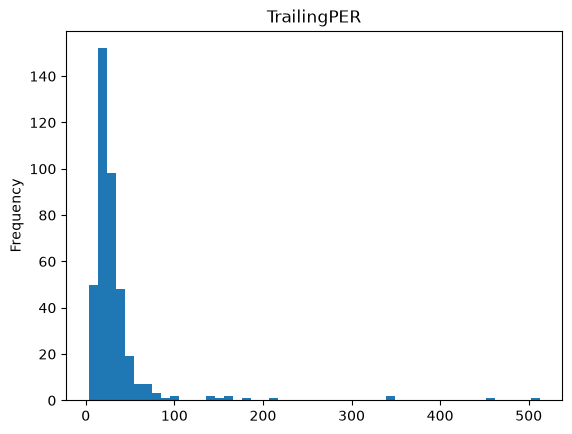

In [ ]:
df["TrailingPER"].plot.hist(bins=50, title="TrailingPER")
df["TrailingPER"].skew()

Esperado: distribución con fuerte asimetría positiva (cola a la derecha), coeficiente de asimetría ≈ 7.

- 3 pts: histograma + "asimetría positiva/cola derecha".

(b) (3 pts) Histograma de `log(TrailingPER)`. ¿Cómo cambia la asimetría?

np.float64(1.1024308387384039)

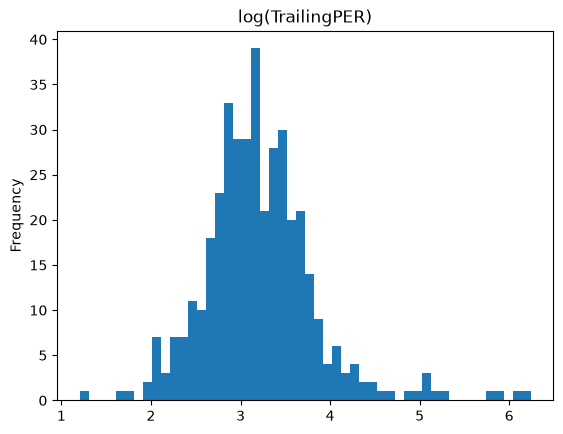

In [ ]:
df["lPER"].plot.hist(bins=50, title="log(TrailingPER)")
df["lPER"].skew()

Esperado: la asimetría se reduce mucho (≈ 1,1), la distribución es mucho más simétrica / cercana a una normal, y los outliers pesan menos. Sigue habiendo algo de cola derecha.

- 3 pts: histograma + compara explícitamente con (a).

## Pregunta 4
(a) (5 pts) $\ln(TrailingPER)=\beta_0+\beta_1EPSGrowth+u$, con y sin errores robustos.

In [ ]:
m4 = smf.ols("lPER ~ EPSGrowth", data=df)
print(m4.fit().summary().tables[1])
print(m4.fit(cov_type="HC1").summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.1861      0.034     95.013      0.000       3.120       3.252
EPSGrowth      0.0462      0.019      2.408      0.016       0.008       0.084
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.1861      0.035     90.319      0.000       3.117       3.255
EPSGrowth      0.0462      0.038      1.217      0.224      -0.028       0.121


Resultados de referencia

| | Coef. EPSGrowth | EE | p-valor |
|---|---|---|---|
| EE clásicos | 0,046 | 0,019 | 0,016 |
| EE robustos HC1 | 0,046 | 0,038 | 0,224 |

(HC3 da p ≈ 0,31, ambas opciones se vieron en los labs y son válidas.)

Interpretación esperada:
- El coeficiente no cambia, solo cambia el error estándar.
- Con EE clásicos EPSGrowth parece significativo al 5%, con EE robustos deja de serlo. Hay heterocedasticidad y los EE clásicos subestiman la incertidumbre.
- Interpretación del coeficiente (log-nivel): un aumento de 1 unidad en EPSGrowth (100 p.p. de crecimiento) se asocia con un PER ≈ 4,6% mayor. Pequeño y no significativo.


(b) (4 pts) ¿Por qué usar `log(TrailingPER)`? Máx. 10 líneas, basado en los datos.

Argumentos esperados:
1. Asimetría y outliers: el PER tiene asimetría ≈ 7 y valores extremos (P3). El log la reduce a ≈ 1,1, por lo que pocas empresas no dominan la estimación MCO.
2. Heterocedasticidad: la varianza del PER crece con su nivel, el log la estabiliza (sin eliminarla del todo, como se vio en (a)).
3. Interpretación: en un modelo log-nivel los coeficientes se leen como cambios porcentuales del PER, más natural para un múltiplo (un aumento de 5 puntos no significa lo mismo en un PER de 10 que en uno de 200).
4. Los residuos quedan más cercanos a la normalidad, lo que hace más confiable la inferencia en muestras finitas.

## Pregunta 5
(a) (5 pts) Modelo múltiple con EE robustos. ¿Qué variables son significativas al 5%?

In [ ]:
f5 = "lPER ~ EPSGrowth + ROE + Beta + PayoutRatio + DebtToEquity"
m5 = smf.ols(f5, data=df).fit(cov_type="HC1")
print(m5.summary())

                            OLS Regression Results                            
Dep. Variable:                   lPER   R-squared:                       0.288
Model:                            OLS   Adj. R-squared:                  0.279
Method:                 Least Squares   F-statistic:                     28.60
Date:                Sun, 04 Oct 2026   Prob (F-statistic):           9.90e-25
Time:                        13:47:04   Log-Likelihood:                -316.13
No. Observations:                 398   AIC:                             644.3
Df Residuals:                     392   BIC:                             668.2
Df Model:                           5                                         
Covariance Type:                  HC1                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        2.6626      0.068     38.991   

Resultados de referencia (HC1). Significativas al 5%: Beta (0,47, p<0,001) y PayoutRatio (0,25, p<0,001). EPSGrowth, ROE y DebtToEquity no son significativas. Si por alguna razón estima otro modelo esta respuesta cambia.

Interpretación (no necesaria para puntaje completo):
- Beta: un aumento de 0,1 en beta se asocia a un PER ≈ 4,7% mayor, ceteris paribus.
- PayoutRatio: 10 p.p. más de payout se asocian a un PER ≈ 2,5% mayor. Consistente con Gordon ($PER = \frac{payout}{r-g}$, con g constante).
- DebtToEquity: coeficiente minúsculo porque está en % y tiene un outlier extremo.

HC3 se puede aplicar


(b) (4 pts) VIF. ¿Qué puedes concluir?

In [ ]:
X = sm.add_constant(df[["EPSGrowth", "ROE", "Beta", "PayoutRatio", "DebtToEquity"]])
pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
          index=X.columns[1:], name="VIF").round(2)

EPSGrowth       1.03
ROE             1.46
Beta            1.07
PayoutRatio     1.03
DebtToEquity    1.41
Name: VIF, dtype: float64

Esperado: todos los VIF entre 1,0 y 1,5 muy por debajo de 5 o 10, por lo que no hay problema de multicolinealidad.

## Pregunta 6
(a) (4 pts) Modelo de P5 + dummies sectoriales, EE robustos.

In [ ]:
m6 = smf.ols(f5 + " + C(Sector)", data=df).fit(cov_type="HC1")
print(m6.summary().tables[1])

                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                               2.7134      0.148     18.395      0.000       2.424       3.003
C(Sector)[T.Communication Services]    -0.2032      0.183     -1.113      0.266      -0.561       0.155
C(Sector)[T.Consumer Cyclical]         -0.2077      0.168     -1.240      0.215      -0.536       0.121
C(Sector)[T.Consumer Defensive]         0.0827      0.159      0.519      0.603      -0.229       0.395
C(Sector)[T.Energy]                    -0.1788      0.165     -1.085      0.278      -0.502       0.144
C(Sector)[T.Financial Services]        -0.2562      0.138     -1.851      0.064      -0.527       0.015
C(Sector)[T.Healthcare]                 0.1552      0.143      1.084      0.278      -0.125       0.436
C(Sector)[T.Industrials]                0.1280      0.136      0

Esperado:
- Categoría base: Basic Materials. Es válido elegir otra base o crear dummies con `pd.get_dummies(..., drop_first=True)`

Se busca que identifique variables significativas + menciona categoría base o interpreta una dummy.

(b) (4 pts) ¿Son las dummies sectoriales conjuntamente significativas al 5%?

In [ ]:
m6.f_test([p for p in m6.params.index if "Sector" in p])

<class 'statsmodels.stats.contrast.ContrastResults'>
<F test: F=5.120677847841241, p=4.923970279342562e-07, df_denom=382, df_num=10>

Resultado de referencia: F(10, 382) ≈ 5,12, p < 0,001. Se rechaza H0, las dummies son conjuntamente significativas.

## Pregunta 7
(a) (4 pts) Efecto de `PayoutRatio` sobre `log(PER)`, distinto para Tecnología.

Modelo base esperado (interacción con dummy):
$$\ln(PER)=\beta_0+\beta_1 Payout+\beta_2 Tech+\beta_3 (Payout\times Tech)+u$$

In [ ]:
df["Tech"] = (df["Sector"] == "Technology").astype(int)
m7 = smf.ols("lPER ~ PayoutRatio * Tech", data=df).fit(cov_type="HC1")
print(m7.summary().tables[1])

                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            3.0215      0.036     82.849      0.000       2.950       3.093
PayoutRatio          0.2478      0.041      6.040      0.000       0.167       0.328
Tech                 0.5496      0.126      4.374      0.000       0.303       0.796
PayoutRatio:Tech    -0.5675      0.307     -1.848      0.065      -1.169       0.034


Variantes válidas:
- Agregar los controles de P5 (`EPSGrowth + ROE + Beta + DebtToEquity`).
- Interactuar con todas las dummies de sector y mirar la de Tecnología.

Errores a descontar:
- Incluir solo la interacción `Payout:Tech` sin la dummy `Tech` (es importante, visto en ayudantía).

(b) (5 pts) Al 10%, ¿qué concluyes sobre el efecto diferencial? Interpreta el coeficiente.

| | coef | p (HC1) |
|---|---|---|
| PayoutRatio | 0,248 | <0,001 |
| Tech | 0,550 | <0,001 |
| PayoutRatio × Tech | −0,568 | 0,065 |

Interpretación esperada con HC1 y especificación aplicada:
- Al 10% el efecto diferencial es significativo: el payout se relaciona con el PER de forma distinta en Tecnología.
- Fuera de Tecnología: 10 p.p. más de payout se asocian a un PER ≈ 2,5% mayor.
- En Tecnología: el efecto total es 0,248 − 0,568 ≈ −0,32, así que 10 p.p. más de payout se asocian a un PER ≈ 3,2% menor. El mercado castiga a las tecnológicas que reparten más dividendos.
- La evidencia es débil (significativa solo al 10%, sensible al tipo de EE, y hay pocas tecnológicas con payout alto).

(c) (4 pts) Como Gerente de Finanzas de una tecnológica, ¿cómo usarías este resultado ante el directorio para justificar reinvertir en vez de pagar dividendos?

Ideas esperadas:
- Argumento a favor: en Tecnología el mercado asocia mayor payout con menor PER, y pagar dividendos puede leerse como señal de falta de oportunidades de crecimiento. Reinvertir es consistente con lo que el mercado valora (si los proyectos rentan más que el costo de capital, ROE > r).
- Matices (al menos uno para puntaje completo):
  - Es una correlación, no causalidad. Subir o bajar el payout no garantiza mover el PER.
  - Evidencia débil (10%, sensible a EE, R² bajo).
  - Reinvertir solo crea valor si existen proyectos con VPN > 0. Si no, retener caja destruye valor (problema de agencia).
  - Teoría de señales / clientela de inversionistas, y que una empresa madura puede tener otra lógica.

- 4 pts: argumento claro ligado al resultado + al menos una limitación. 2–3 pts: argumento sin limitaciones o limitaciones sin argumento. 1 pt: respuesta genérica sin usar el resultado.

## Pregunta 8 (4 pts)
¿Por qué la práctica prefiere $\text{Precio objetivo}=E[EPS]\times PER$ sobre un DCF? Riesgos y limitaciones (máx. 20 líneas).

Por qué se prefiere (2–3 ideas):
- Simple, rápido y comunicable, fácil de comparar entre empresas y analistas.
- Basado en el mercado (valuación relativa): incorpora implícitamente el consenso sobre riesgo y crecimiento.
- Requiere pocos supuestos frente al DCF, que es muy sensible a la tasa de descuento, al crecimiento terminal y a proyecciones de flujos de largo plazo.

Riesgos y limitaciones (2–3 ideas):
- Supone que el PER histórico se mantiene, ignora reversión a la media, cambios de ciclo o de régimen de tasas.
- Utilidades negativas o transitoriamente bajas generan un PER sin sentido o explosivo (P2c: Genuine Parts, PER 512).
- Inconsistencia: multiplicar EPS esperado por PER trailing (debería usarse un PER forward).
- Si el mercado está sobrevalorado, el múltiplo traspasa el error al precio objetivo.
- Ignora diferencias en riesgo, apalancamiento, payout y crecimiento entre empresas. Se valora conectarlo con la tarea: las regresiones muestran que el PER depende de beta, payout y sector, y aun así el R² ≈ 0,3, o sea, gran parte de la variación del PER no se explica con fundamentales. Un PER "histórico" o "del sector" es un ancla imprecisa.
- Calidad contable / manipulación de utilidades.
